In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyregtools
from pyregtools.toyproblems.temp_semi_inf_rod import TempSemiInfRod
from pyregtools import regsolvers
from pyregtools import iterativesolvers
from pyregtools import regchoice

In [2]:
def plot_measurement(problem, x_sol = None, source_lim = (0, 250), b_lim = (0, 250)):
    """ Helping function to do specific plots of source terms and measured signals.
    """
    fig, axs = plt.subplots(1, 2, figsize = (9,3))
    axs[0].plot(problem.time[1:], problem.x_true, '--k')
    if x_sol is not None:
        axs[0].plot(problem.time[1:], x_sol, 'royalblue', alpha = 0.8)
    axs[0].grid(linestyle = '--')
    axs[0].set_xlim((0, problem.time[-1]))
    axs[0].set_ylim((source_lim[0],source_lim[1]))
    axs[0].set_xlabel(r'time [s]')
    axs[0].set_ylabel(r'$T(t)$  [K]')
    axs[0].set_title(r'Source field (cond($\mathbf{{A}}) = {:.2e}$)'.format(np.linalg.cond(problem.A)))
    axs[1].plot(problem.time, problem.b_true, '--k', label = r'true meas.')
    if hasattr(problem, "b_noisy"):
        axs[1].plot(problem.time, problem.b_noisy, label = r'Noisy measurement', color = 'royalblue', alpha = 0.8)
    axs[1].grid(linestyle = '--')
    axs[1].set_xlim((0, problem.time[-1]))
    axs[1].set_ylim(b_lim)
    axs[1].legend()
    axs[1].set_xlabel(r'time [s]')
    axs[1].set_ylabel(r'$T(t)$  [K]')
    axs[1].set_title(r'Measured temperature ($x_m = {}$ m)'.format(problem.xm))
    plt.tight_layout()

In [69]:
problem = TempSemiInfRod(xm=0.85, alpha = 1.0, T0 = 100, tmax = 10, fs = 20) # instantiate
problem.sens_mtx() # build the sensing matrix
snr = 30

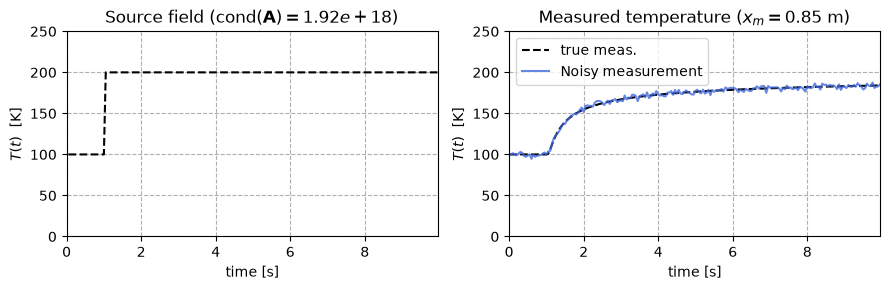

In [70]:
problem.temp_step(time_step=1.0, T_source=200.0)
problem.noiseless_meas() # compute true measurement
problem.add_noise(snr = snr) # add some noise
plot_measurement(problem)

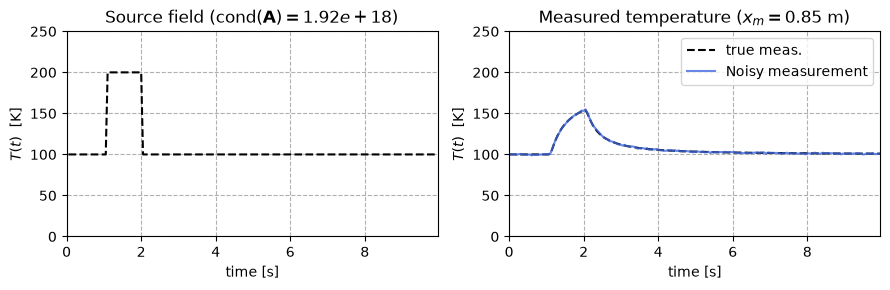

In [71]:
problem.temp_square_pulse(time_init=1, time_end=2, T_source=200) # create a source term
problem.noiseless_meas() # compute true measurement
problem.add_noise(snr = snr) # add some noise
plot_measurement(problem)

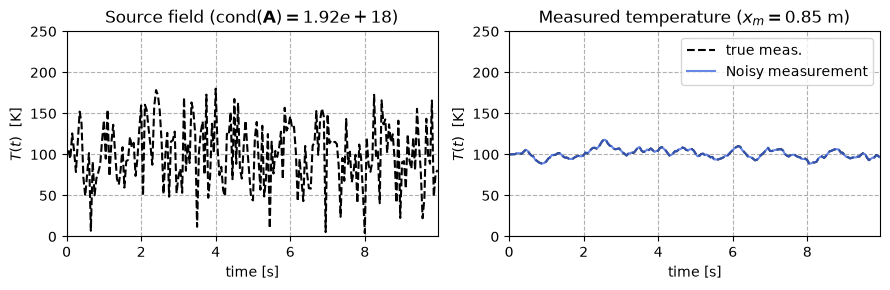

In [72]:
problem.temp_random(std_temp=40.0, seed=0)
problem.noiseless_meas() # compute true measurement
problem.add_noise(snr = snr) # add some noise
plot_measurement(problem)

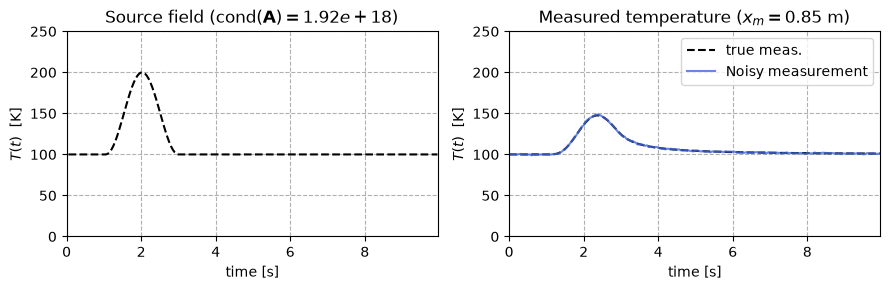

In [85]:
problem.temp_hann_pulse(time_init=1.0, time_end=3.0, T_source=200.0) # create a source term
problem.noiseless_meas() # compute true measurement
problem.add_noise(snr = snr) # add some noise
plot_measurement(problem)



Baseline temperature temperature is 98.8673


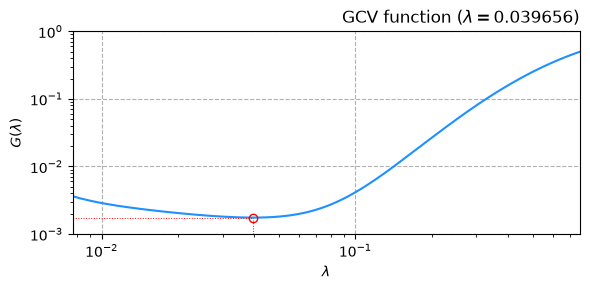

In [104]:
base_temp = np.amin(problem.b_noisy)
print("Baseline temperature temperature is {:.4f}".format(base_temp))
u, s, v = regsolvers.csvd(problem.A[1:, :])
lam_opt = regchoice.gcv_lambda(u, s, problem.b_noisy[1:]-base_temp, plotit = True, r_min= 1e-2)
x_est = regsolvers.tikhonov(u, s, v, problem.b_noisy[1:]-base_temp, lam_opt)

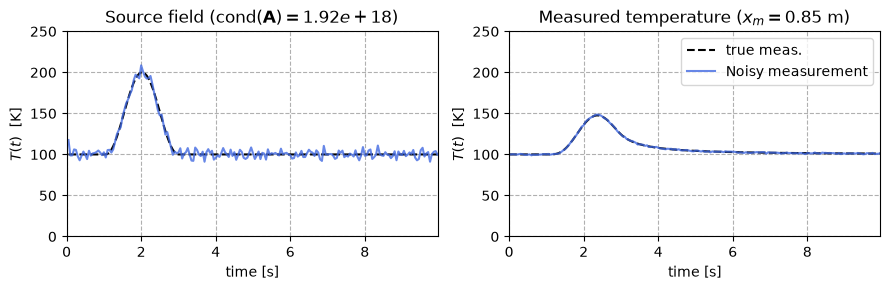

In [105]:
x_est += base_temp
plot_measurement(problem, x_sol = x_est)

In [106]:
num_iterations = 500
omega = 0.05*2/s[0]**2
x_est_h, sol_norms, res_norms = iterativesolvers.landweber(problem.A, problem.b_noisy-base_temp, 
                                                           omega = omega, x0 = None, max_it=num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (199, 500)


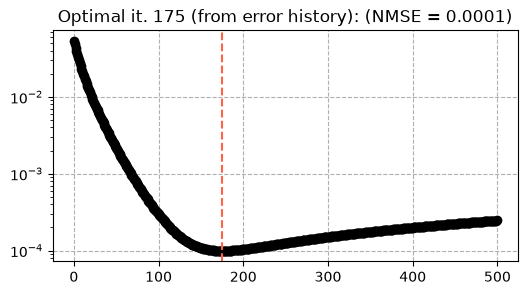

In [108]:
error_hist = pyregtools.utils.nmse_fun(x_est_h+base_temp, problem.x_true[:, None], axis=0)
k_opt = np.argmin(error_hist)
plt.figure(figsize = (6,3))
plt.semilogy(np.arange(len(error_hist)), error_hist, '-ok')
plt.axvline(k_opt, linestyle = '--', color = 'tomato')
plt.title("Optimal it. {} (from error history): (NMSE = {:.4f})".format(k_opt, error_hist[k_opt]))
plt.grid(linestyle = '--')
#plt.ylim((0.003, 0.03))
plt.show()

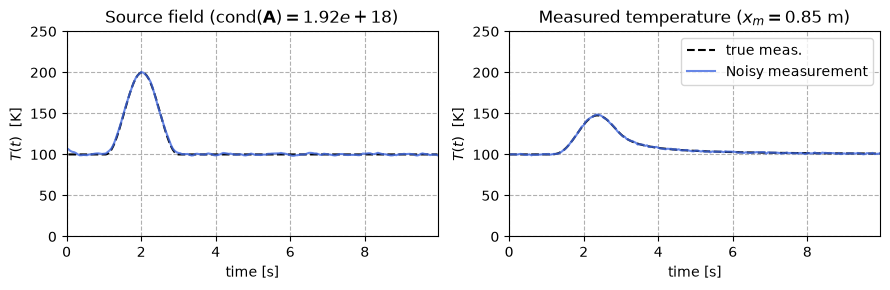

In [109]:
x_est = x_est_h[:,k_opt] + base_temp
plot_measurement(problem, x_sol = x_est)

In [111]:
num_iterations = 100
x_est_h, sol_norms, res_norms = iterativesolvers.cgls(problem.A, problem.b_noisy-base_temp, max_it=num_iterations)
print("Shape of Solution history: {}".format(x_est_h.shape))

Shape of Solution history: (199, 100)


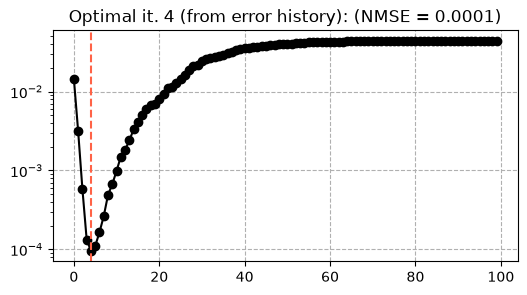

In [112]:
error_hist = pyregtools.utils.nmse_fun(x_est_h+base_temp, problem.x_true[:, None], axis=0)
k_opt = np.argmin(error_hist)

plt.figure(figsize = (6,3))
plt.semilogy(np.arange(len(error_hist)), error_hist, '-ok')
plt.axvline(k_opt, linestyle = '--', color = 'tomato')
plt.title("Optimal it. {} (from error history): (NMSE = {:.4f})".format(k_opt, error_hist[k_opt]))
plt.grid(linestyle = '--')
#plt.ylim((0.003, 0.03))
plt.show()

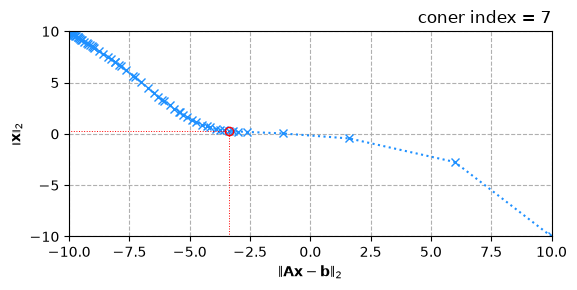

In [113]:
k_l = regchoice.lcurve_discrete(res_norms, sol_norms, plotit=True)

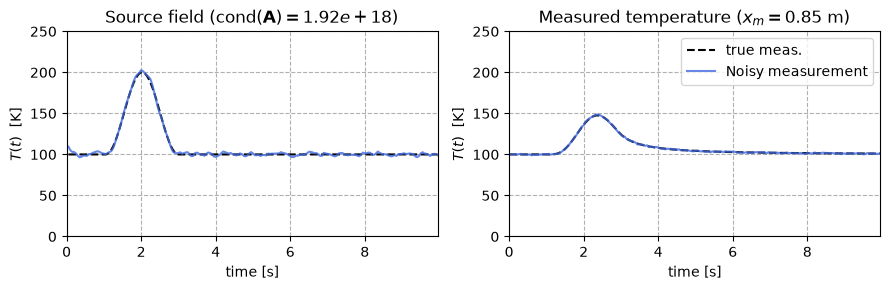

In [114]:
x_est = x_est_h[:,k_l] + base_temp
plot_measurement(problem, x_sol = x_est)